# Transformations

1. Translation
2. Rotation
3. Scaling
4. Projective

In [ ]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

In [ ]:
def draw_quadrangle(X, Y, color = 'b', limX = [-50, 50], limY = [-50, 50]):
    #Vẽ hình tứ giác.
    plt.scatter(X,Y, color = color)
    plt.xlim(limX)
    plt.ylim(limY)


In [ ]:
def transform(X, Y, T = np.eye(3), p = False):
    row_ones = np.ones(len(X))
    homogeneous_coordinates = np.concatenate(([X], [Y], [row_ones]), axis = 0)
    new_coordinates = T @ homogeneous_coordinates
    new_X = new_coordinates[0, :]/new_coordinates[2, :]
    new_Y = new_coordinates[1, :]/new_coordinates[2, :]
    if(p):
        return new_X.astype('int32'), new_Y.astype('int32')
    else:
        return new_X, new_Y


## Initial picture

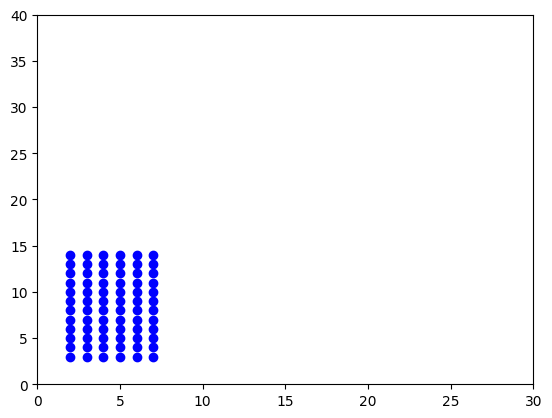

In [ ]:
# Tạo ra một lưới các điểm ảnh
f1, f2 = np.meshgrid(np.arange(2,8), np.arange(3,15))
# Biến đổi ma trận f1 thành một mảng 1 chiều
X = f1.flatten()
# Biến đổi ma trận f2 thành một mảng 1 chiều
Y = f2.flatten()
# Vẽ hình tứ giác dựa trên các tọa độ X và Y
draw_quadrangle(X, Y, limX = [0, 30], limY = [0, 40])


## 1. Translation transformation

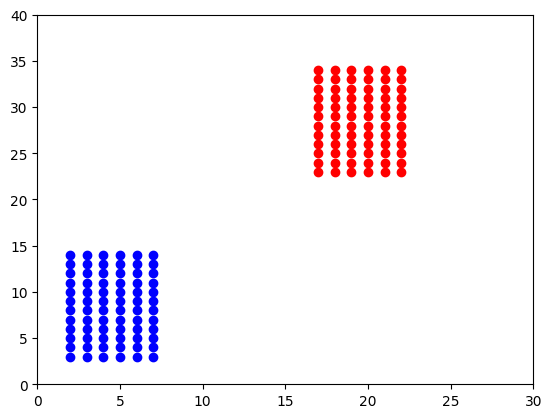

In [ ]:
# Tạo ma trận biến đổi T
T = np.array([[1, 0, 15], [0, 1, 20], [0, 0, 1]])
# Áp dụng hàm transform để biến đổi các tọa độ X và Y dựa trên ma trận biến đổi T
new_X, new_Y = transform(X,Y,T)
# Vẽ hình tứ giác đầu tiên với màu xanh dương
plt.figure()
draw_quadrangle(X, Y, color= 'b', limX = [0, 30], limY = [0, 40])
# Vẽ hình tứ giác thứ hai đã được biến đổi với màu đỏ và giới hạn trục x từ 0 đến 30, trục y từ 0 đến 40
draw_quadrangle(new_X, new_Y, color = 'r', limX = [0, 30], limY = [0, 40])
plt.show()

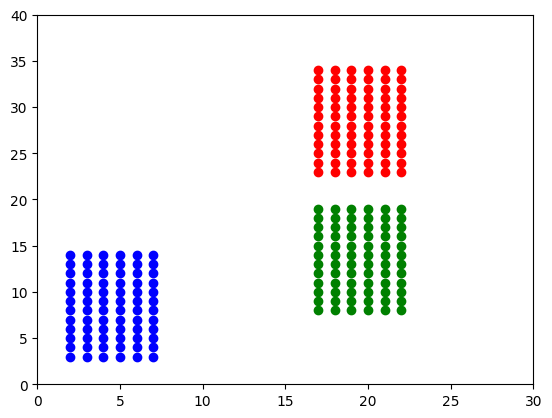

In [ ]:
# Tạo ma trận biến đổi T1
T1 = np.array([[1, 0, 15], [0, 1, 20], [0, 0, 1]])
# Áp dụng hàm transform để biến đổi các tọa độ X và Y dựa trên ma trận biến đổi T1
new_X1, new_Y1 = transform(X,Y,T1)
# Tạo ma trận biến đổi T2 cho hình thứ ba
T2 = np.array([[1, 0, 15], [0, 1, 5], [0, 0, 1]])
# Áp dụng hàm transform để biến đổi các tọa độ X và Y dựa trên ma trận biến đổi T2
new_X2, new_Y2 = transform(X,Y,T2)

# Vẽ hình tứ giác đầu tiên với màu xanh dương
draw_quadrangle(X, Y, color= 'b', limX = [0, 30], limY = [0, 40])
# Vẽ hình tứ giác thứ hai đã được biến đổi với màu đỏ
draw_quadrangle(new_X1, new_Y1, color= 'r',limX = [0, 30], limY = [0, 40])
# Vẽ hình tứ giác thứ ba đã được biến đổi với màu xanh lá cây
draw_quadrangle(new_X2, new_Y2, color= 'g',limX = [0, 30], limY = [0, 40])

# Hiển thị đồ thị
plt.show()

## 2. Rotation transformation




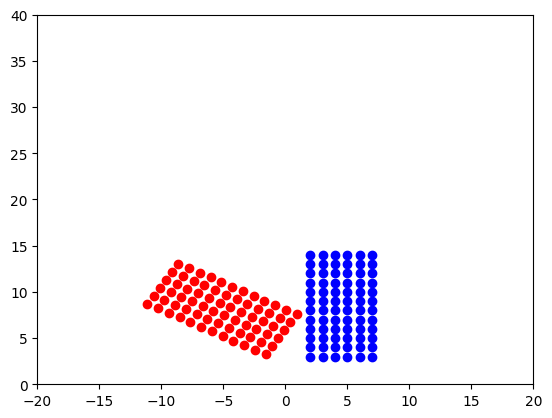

In [ ]:
# Góc quay
theta_deg = 60
# Chuyển đổi thành radian
theta_rad = np.deg2rad(theta_deg)

# Tạo ma trận biến đổi T dựa trên góc quay theta
R = np.array([[np.cos(theta_rad), -np.sin(theta_rad), 0],
              [np.sin(theta_rad), np.cos(theta_rad), 0],
              [0, 0, 1]])
# Áp dụng hàm transform để biến đổi các tọa độ X và Y dựa trên ma trận biến đổi T
new_X, new_Y = transform(X,Y,R)
# Vẽ hình tứ giác ban đầu với màu xanh dương
plt.figure()
draw_quadrangle(X, Y, color= 'b', limX = [0, 30], limY = [0, 40])
# Vẽ hình tứ giác sau khi đã được biến đổi với màu đỏ và giới hạn trục x từ -20 đến 20, trục y từ 0 đến 40
draw_quadrangle(new_X, new_Y, color= 'r', limX = [-20, 20], limY = [0, 40])
plt.show()


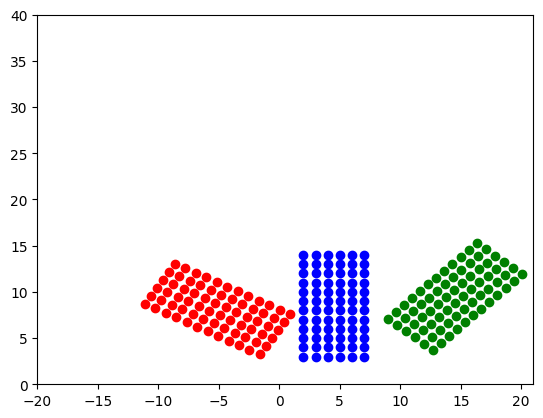

In [ ]:
# Góc quay
theta_deg = 60
theta_g = 42
# Chuyển đổi thành radian
theta_rad = np.deg2rad(theta_deg)
theta_radg = np.deg2rad(theta_g)

# Tính toán dịch chuyển cho tứ giác màu xanh lá
center_X = (np.max(X) + np.min(X))/2
center_Y = (np.max(Y) + np.min(Y))/2

# Ma trận dịch chuyển cho tứ giác xanh lá

R = np.array([[np.cos(theta_rad), -np.sin(theta_rad), 0],
              [np.sin(theta_rad), np.cos(theta_rad), 0],
              [0, 0, 1]])

new_X, new_Y = transform(X,Y,R)

T_O = np.array([[1,0,-center_X],
                   [0,1,-center_Y],
                   [0,0,1]])

Rg = np.array([[np.cos(theta_radg), np.sin(theta_radg), 0],
              [-np.sin(theta_radg), np.cos(theta_radg), 0],
              [0, 0, 1]])

T_back = np.array([[1,0,center_X],
                      [0,1,center_Y],
                      [0,0,1]])

T_right = np.array([[1,0,10],
                       [0,1,1],
                       [0,0,1]])
T_combine =  T_right @ T_back @ Rg @ T_O

# Áp dụng phép dịch chuyển
new_X2, new_Y2 = transform(X,Y,T_combine)

# Vẽ lại tứ giác màu xanh lá đã dịch chuyển
plt.figure()
draw_quadrangle(X, Y, color= 'b', limX = [0, 30], limY = [0, 40])
draw_quadrangle(new_X, new_Y, color= 'r', limX = [-20, 21], limY = [0, 40])
draw_quadrangle(new_X2, new_Y2, color= 'g', limX = [-20, 21], limY = [0, 40])
plt.show()

## 3. Scaling transformation

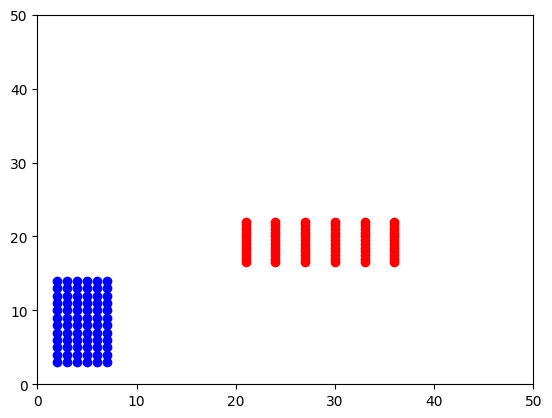

In [ ]:
Sc = np.array([[3, 0, 15],
                         [0, 0.5, 15],
                         [0, 0, 1]])
new_X, new_Y = transform(X,Y,Sc)
plt.figure()
draw_quadrangle(X,Y, color = 'b',limX = [0,50],limY = [0,50])
draw_quadrangle(new_X,new_Y, color ='r', limX=[0,50],limY=[0,50])
plt.show()


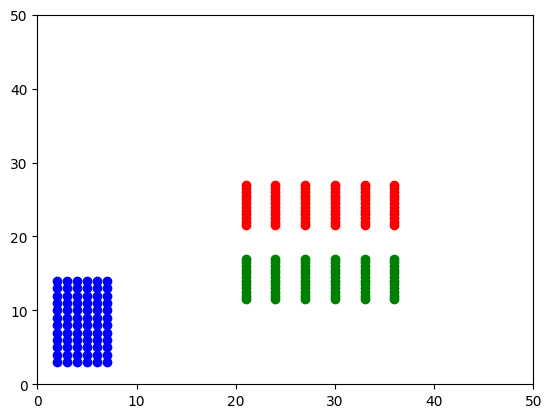

In [ ]:
Sc = np.array([[3, 0, 15],
                         [0, 0.5, 20],
                         [0, 0, 1]])
Sc2 = np.array([[3,0,15],
                          [0,0.5,10],
                          [0,0,1]])
new_X, new_Y = transform(X,Y,Sc)
new_X2, new_Y2 = transform(X,Y,Sc2)
plt.figure()
draw_quadrangle(X,Y, color = 'b',limX = [0,50],limY = [0,50])
draw_quadrangle(new_X,new_Y, color ='r', limX=[0,50],limY=[0,50])
draw_quadrangle(new_X2,new_Y2, color ='g', limX=[0,50],limY=[0,50])
plt.show()


## 4. Projective transformation

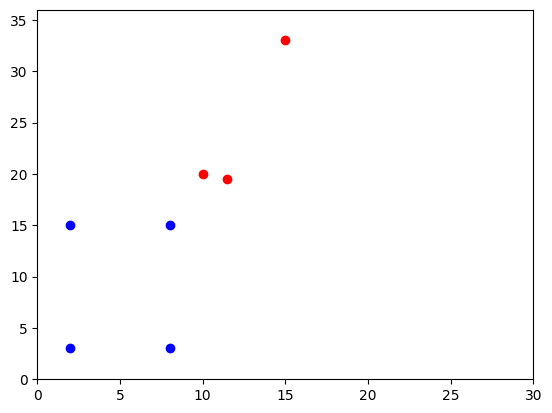

In [85]:
go = np.array([[2,3],
                [2,15],
                [8,3],
                [8,15]])

end = np.array([[10,20],
                [11,40],
                [11.5,19.5],
                [15,33]])

x, y, u, v = go[:,0], go[:,1], end[:,0], end[:,1]
A = np.zeros((9,9))
a = 0
for i in range(4):
    A[a,:] = np.array([-x[i],
                       -y[i],
                       -1,
                       0,
                       0,
                       0,
                       x[i]*u[i],
                       y[i]*u[i],
                       u[i]])
    A[a+1,:] = np.array([0,
                         0,
                         0,
                         -x[i],
                         -y[i],
                         -1,
                         x[i]*v[i],
                         y[i]*v[i],
                         v[i]])
    a+=2
A[8, 8] = 1
b = [0]*8 + [1]

R = np.reshape(np.linalg.solve(A, b), (3,3))
X_new, Y_new = transform(X, Y, R)
draw_quadrangle(X, Y, 'b', limX = [0, 30], limY = [0, 36])
draw_quadrangle(X_new, Y_new, 'r', limX = [0, 30], limY = [0, 36])

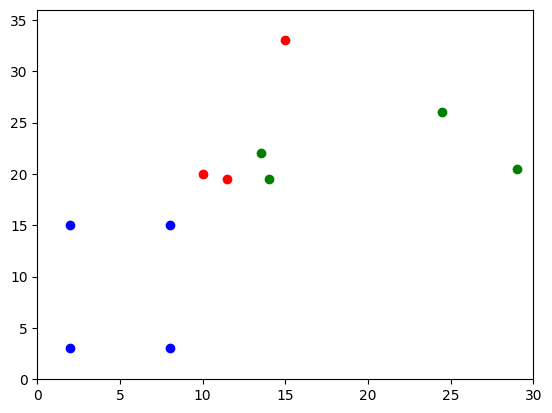

In [93]:
# Vẽ tứ giác ban đầu
go = np.array([[2,3],
               [2,15],
               [8,3],
               [8,15]])

# Ma trận biến đổi cho tứ giác đỏ
end_r = np.array([[10,20],
                [11,40],
                [11.5,19.5],
                [15,33]])

x, y, u, v = go[:,0], go[:,1], end_r[:,0], end_r[:,1]
A = np.zeros((9,9))
a = 0
for i in range(4):
    A[a,:] = np.array([-x[i],
                       -y[i],
                       -1,
                       0,
                       0,
                       0,
                       x[i]*u[i],
                       y[i]*u[i],
                       u[i]])
    A[a+1,:] = np.array([0,
                         0,
                         0,
                         -x[i],
                         -y[i],
                         -1,
                         x[i]*v[i],
                         y[i]*v[i],
                         v[i]])
    a+=2
A[8, 8] = 1
b = [0]*8 + [1]

R_r = np.reshape(np.linalg.solve(A, b), (3,3))
X_r, Y_r = transform(X, Y, R_r)

# Ma trận biến đổi cho tứ giác xanh lá cây
end_g = np.array([[13.5,14.5],
                  [24.5,18.5],
                  [14,12],
                  [29,13]])
x, y, u, v = go[:,0], go[:,1], end_g[:,0], end_g[:,1]
A = np.zeros((9,9))
a = 0
for i in range(4):
    A[a,:] = np.array([-x[i],
                       -y[i],
                       -1,
                       0,
                       0,
                       0,
                       x[i]*u[i],
                       y[i]*u[i],
                       u[i]])
    A[a+1,:] = np.array([0,
                         0,
                         0,
                         -x[i],
                         -y[i],
                         -1,
                         x[i]*v[i],
                         y[i]*v[i],
                         v[i]])
    a+=2
A[8, 8] = 1
b = [0]*8 + [1]

R_g = np.reshape(np.linalg.solve(A, b), (3,3))
X_g, Y_g = transform(X, Y, R_g)


# Tính toán tọa độ của cạnh dưới cùng (min y) và cạnh giữa
ymin_r = np.min(Y_r)
ymin_g = np.min(Y_g)


# Tính toán khoảng cách dịch chuyển
dy = ymin_r - ymin_g
# Ma trận dịch chuyển điều chỉnh
T_trs = np.array([[1, 0, 0],
                     [0, 1, dy],
                     [0, 0, 1]])
X_g_fix, Y_g_fix = transform(X_g, Y_g, T_trs)

# Vẽ tứ giác đỏ và xanh lá cây đã dịch chuyển
draw_quadrangle(X, Y, 'b', limX = [0, 30], limY = [0, 36])
draw_quadrangle(X_r, Y_r, 'r', limX = [0, 30], limY = [0, 36])
draw_quadrangle(X_g_fix, Y_g_fix, 'g', limX = [0, 30], limY = [0, 36])

# Hiển thị kết quả
plt.show()